# 01 Exploratory Data Analysis

This notebook answers six questions:

1. How large is the statement-level table?
2. How many unique customers does it contain?
3. How many monthly records are available per customer?
4. What time period is covered?
5. Which columns and missingness patterns are present?
6. How imbalanced is the binary target?

The compressed Feather file is scanned in record batches, which avoids loading all 5.5 million rows into memory.


In [2]:
from pathlib import Path

def find_project_root() -> Path:
    """Use the parent of the notebook working directory as the project root."""
    project_root = Path.cwd().resolve().parent
    if not (project_root / 'data').is_dir():
        raise FileNotFoundError(
            "Expected the project data directory one level above the current working directory."
        )
    return project_root

from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.ipc as ipc

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


### 1. Locate the project artifacts


In [ ]:
PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / 'data' / 'train_data_float16_zstd.feather'
LABEL_PATH = PROJECT_ROOT / 'data' / 'train_labels.csv'

print(f'Input data{DATA_PATH.resolve()}')
print(f'File size：{DATA_PATH.stat().st_size / 2**30:.2f} GiB')
print(f'Label data：{LABEL_PATH.resolve()}')


### 2. Measure the table size

Arrow file metadata provides row count, column count, batch count, names, and dtypes directly.

In [4]:
with pa.memory_map(str(DATA_PATH), 'r') as source:
    reader = ipc.open_file(source)
    column_names = reader.schema.names
    column_types = [str(field.type) for field in reader.schema]
    number_of_batches = reader.num_record_batches
    number_of_rows = sum(reader.get_batch(i).num_rows for i in range(number_of_batches))

print(f'Rows：{number_of_rows:,}')
print(f'Columns：{len(column_names)}')
print(f'Batches：{number_of_batches}')


Rows：5,531,451
Columns：190
Batches：56


### 3. Inspect representative rows

Compressed `customer_ID` values may be negative because the original 64-bit hexadecimal suffix is interpreted as signed `int64`. Uniqueness is preserved and the sign has no actual meaning.


In [5]:
with pa.memory_map(str(DATA_PATH), 'r') as source:
    reader = ipc.open_file(source)
    first_10_rows = reader.get_batch(0).slice(0, 10).to_pandas()

first_10_rows


,customer_ID,S_2,P_2,D_39,B_1,B_2,R_1,S_3,D_41,B_3,D_42,D_43,D_44,B_4,D_45,...,D_132,D_133,R_28,D_134,D_135,D_136,D_137,D_138,D_139,D_140,D_141,D_142,D_143,D_144,D_145
0,-4532153018459703766,2017-03-09,0.9385,0.0017,0.0087,1.0068,0.0092,0.1240,0.0088,0.0047,NaN,NaN,0.0006,0.0810,0.7090,...,NaN,0.0043,0.0015,NaN,NaN,NaN,NaN,NaN,0.0024,0.0037,0.0038,NaN,0.0006,0.0006,0.0027
1,-4532153018459703766,2017-04-07,0.9365,0.0058,0.0049,1.0010,0.0062,0.1267,0.0008,0.0027,NaN,NaN,0.0025,0.0694,0.7129,...,NaN,0.0075,0.0049,NaN,NaN,NaN,NaN,NaN,0.0040,0.0032,0.0050,NaN,0.0096,0.0055,0.0092
2,-4532153018459703766,2017-05-28,0.9541,0.0915,0.0217,1.0098,0.0068,0.1240,0.0076,0.0094,NaN,NaN,0.0076,0.0688,0.7207,...,NaN,0.0092,0.0091,NaN,NaN,NaN,NaN,NaN,0.0033,0.0073,0.0004,NaN,0.0034,0.0070,0.0026
3,-4532153018459703766,2017-06-13,0.9604,0.0025,0.0137,1.0029,0.0014,0.1172,0.0007,0.0055,NaN,NaN,0.0064,0.0556,0.7241,...,NaN,0.0072,0.0024,NaN,NaN,NaN,NaN,NaN,0.0061,0.0045,0.0032,NaN,0.0084,0.0065,0.0096
4,-4532153018459703766,2017-07-16,0.9473,0.0025,0.0152,1.0010,0.0076,0.1173,0.0047,0.0093,NaN,NaN,0.0077,0.0388,0.7207,...,NaN,0.0063,0.0045,NaN,NaN,NaN,NaN,NaN,0.0037,0.0049,0.0089,NaN,0.0017,0.0081,0.0098
5,-4532153018459703766,2017-08-04,0.9458,0.0017,0.0079,1.0049,0.0042,0.1110,0.0099,0.0099,NaN,NaN,0.0041,0.0273,0.7212,...,NaN,0.0030,0.0073,NaN,NaN,NaN,NaN,NaN,0.0019,0.0086,0.0045,NaN,0.0007,0.0022,0.0029
6,-4532153018459703766,2017-09-18,0.9409,0.0022,0.0189,1.0078,0.0045,0.1033,0.0066,0.0008,NaN,NaN,0.0094,0.0066,0.7217,...,NaN,0.0084,0.0045,NaN,NaN,NaN,NaN,NaN,0.0013,0.0044,0.0094,NaN,0.0077,0.0077,0.0022
7,-4532153018459703766,2017-10-08,0.9146,0.0030,0.0143,1.0000,0.0003,0.1081,0.0095,0.0078,NaN,NaN,0.0014,0.0057,0.7231,...,NaN,0.0003,0.0001,NaN,NaN,NaN,NaN,NaN,0.0024,0.0085,0.0056,NaN,0.0018,0.0096,0.0074
8,-4532153018459703766,2017-11-20,0.9507,0.0099,0.0169,1.0039,0.0018,0.1028,0.0025,0.0098,NaN,NaN,0.0026,0.0137,0.7310,...,NaN,0.0004,0.0057,NaN,NaN,NaN,NaN,NaN,0.0097,0.0040,0.0079,NaN,0.0087,0.0044,0.0010
9,-4532153018459703766,2017-12-04,0.8687,0.0011,0.0019,1.0078,0.0018,0.1005,0.0046,0.0061,NaN,NaN,0.0076,0.0052,0.7349,...,NaN,0.0037,0.0012,NaN,NaN,NaN,NaN,NaN,0.0036,0.0096,0.0073,NaN,0.0088,0.0048,0.0091


### 4. Review the feature schema

AMEX anonymizes feature semantics, but prefixes provide a general idea:

- `D_*`: delinquency-related variables
- `S_*`: spend-related variables
- `P_*`: payment-related variables
- `B_*`: balance-related variables
- `R_*`: risk-related variables

In [6]:
column_info = pd.DataFrame({
    'column_name': column_names,
    'data_type': column_types,
})

display(column_info)

feature_groups = Counter(
    name.split('_')[0] if '_' in name else name
    for name in column_names
    if name not in ['customer_ID', 'S_2']
)
print('Value counts：', dict(sorted(feature_groups.items())))


,column_name,data_type
0,customer_ID,int64
1,S_2,date32[day]
2,P_2,halffloat
3,D_39,halffloat
4,B_1,halffloat
...,...,...
185,D_141,halffloat
186,D_142,halffloat
187,D_143,halffloat
188,D_144,halffloat


Value counts： {'B': 40, 'D': 96, 'P': 3, 'R': 28, 'S': 21}


### 5. customer and time granularity

Each row is a monthly statement, so a customer can appear repeatedly. 

In [7]:
records_per_customer = pd.Series(dtype='int64')
minimum_date = None
maximum_date = None

with pa.memory_map(str(DATA_PATH), 'r') as source:
    reader = ipc.open_file(source)
    customer_index = reader.schema.get_field_index('customer_ID')
    date_index = reader.schema.get_field_index('S_2')

    for batch_number in range(reader.num_record_batches):
        batch = reader.get_batch(batch_number)
        customer_ids = batch.column(customer_index).to_pandas()
        dates = batch.column(date_index).to_pandas()

        batch_counts = customer_ids.value_counts()
        records_per_customer = records_per_customer.add(batch_counts, fill_value=0)

        batch_minimum = dates.min()
        batch_maximum = dates.max()
        minimum_date = batch_minimum if minimum_date is None else min(minimum_date, batch_minimum)
        maximum_date = batch_maximum if maximum_date is None else max(maximum_date, batch_maximum)

records_per_customer = records_per_customer.astype('int64')

print(f'Unique customers：{records_per_customer.size:,}')
print(f'Earliest record date：{minimum_date}')
print(f'Latest record date：{maximum_date}')
print('\nSummary for records per customer：')
display(records_per_customer.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame('records'))


Unique customers：458,913
Earliest record date：2017-03-01
Latest record date：2018-03-31

Summary for records per customer：


,records
count,"458,913.0000"
mean,12.0534
std,2.6103
min,1.0000
25%,13.0000
50%,13.0000
75%,13.0000
90%,13.0000
99%,13.0000
max,13.0000


,number_of_customers
1,5120
2,6098
3,5778
4,4673
5,4671
6,5515
7,5198
8,6110
9,6411
10,6721


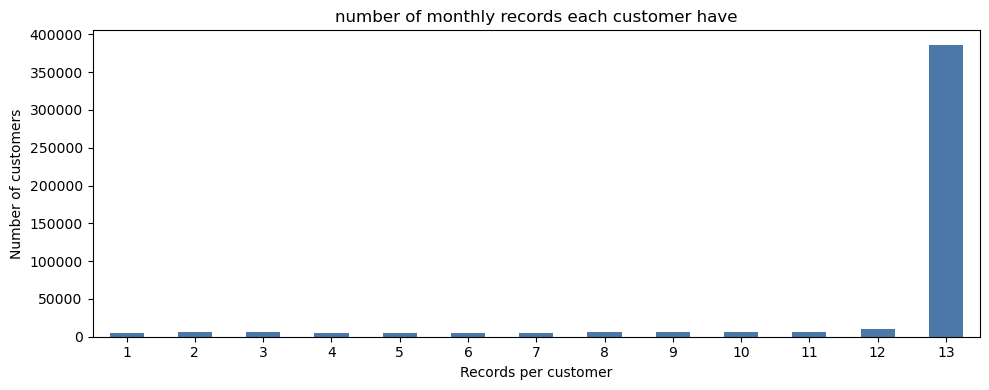

In [8]:
record_count_distribution = records_per_customer.value_counts().sort_index()

display(
    record_count_distribution.rename('number_of_customers').to_frame()
)

record_count_distribution.plot(kind='bar', figsize=(10, 4), color='#4C78A8')
plt.title('number of monthly records each customer have')
plt.xlabel('Records per customer')
plt.ylabel('Number of customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 6. Estimate missingness

Missing values are a major characteristic of this dataset and may themselves carry risk information. For speed, this section estimates missing rates from the first record batch (about 100,000 rows) rather than claiming an exact full-data calculation.


In [9]:
with pa.memory_map(str(DATA_PATH), 'r') as source:
    reader = ipc.open_file(source)
    sample = reader.get_batch(0).to_pandas()

missing_summary = pd.DataFrame({
    'missing_count': sample.isna().sum(),
    'missing_rate': sample.isna().mean(),
}).sort_values('missing_rate', ascending=False)

print(f'Sample rows：{len(sample):,}')
print('Columns with highest missing rates：')
display(missing_summary.head(20))


Sample rows：100,000
Columns with highest missing rates：


,missing_count,missing_rate
D_87,99927,0.9993
D_88,99850,0.9985
D_108,99470,0.9947
D_111,99366,0.9937
D_110,99366,0.9937
B_39,99327,0.9933
D_73,98851,0.9885
B_42,98645,0.9865
D_134,96384,0.9638
D_138,96384,0.9638


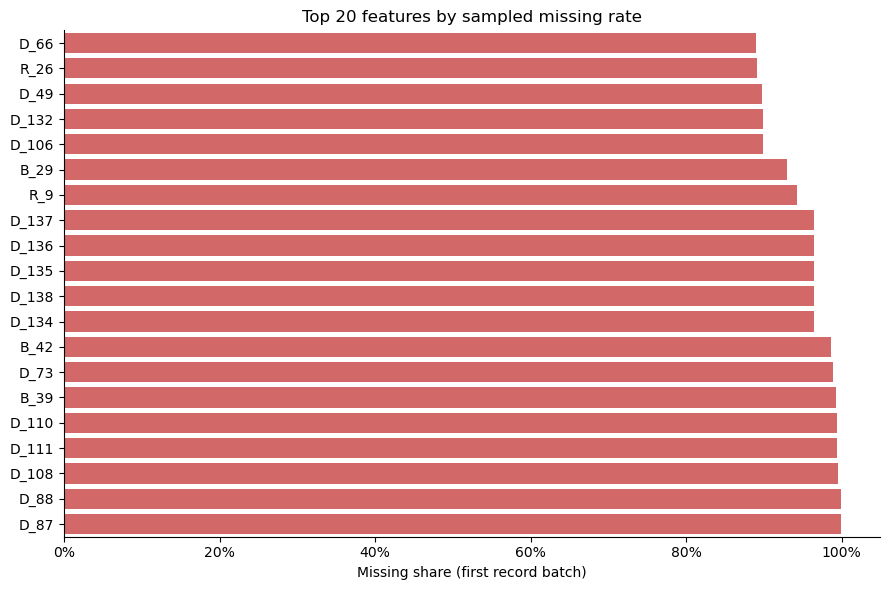

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Highest sampled missing rates
missing_rate = sample.isna().mean().sort_values(ascending=False).head(20).rename('missing_rate').reset_index()
missing_rate.columns = ['feature', 'missing_rate']
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=missing_rate.sort_values('missing_rate'), y='feature', x='missing_rate', color='#E45756', ax=ax)
ax.set(title='Top 20 features by sampled missing rate', xlabel='Missing share (first record batch)', ylabel='')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
sns.despine()
plt.tight_layout()
plt.show()


### 7. Inspect the target distribution

`train_labels.csv` contains one row per customer. A target of 1 denotes the event of interest (default), while 0 denotes no default.


Label rows：458,913
Unique customers：458,913


,customer_count,percentage
target,,
0,340085,0.7411
1,118828,0.2589


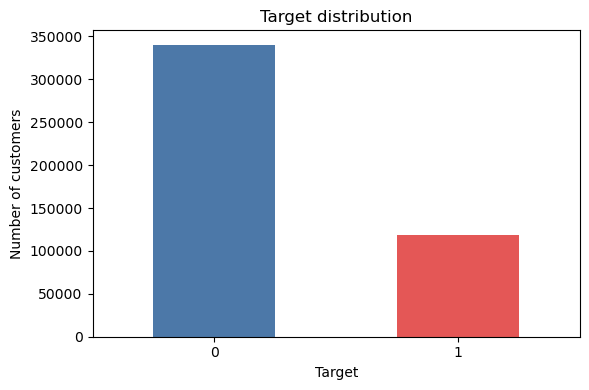

In [14]:
labels = pd.read_csv(LABEL_PATH)

print(f'Label rows：{len(labels):,}')
print(f'Unique customers：{labels.customer_ID.nunique():,}')

target_summary = pd.DataFrame({
    'customer_count': labels['target'].value_counts().sort_index(),
    'percentage': labels['target'].value_counts(normalize=True).sort_index(),
})
display(target_summary)

labels['target'].value_counts().sort_index().plot(
    kind='bar', figsize=(6, 4), color=['#4C78A8', '#E45756']
)
plt.title('Target distribution')
plt.xlabel('Target')
plt.ylabel('Number of customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 8. Key findings and modeling consequence

- The feature table is longitudinal: one customer has multiple monthly statements.
- The label table is customer-level: one target per customer.
- Customers have unequal history lengths and substantial feature missingness.
- Randomly splitting statement rows would leak the same customer into train and validation sets.
